# Nested Kriging Playground: `m4_yearly`

Two-layer nested kriging with Gibbs kernel, whose lengthscale is
itself learned via a nested kriging process (Layer 1).

**Architecture at a glance**
- **Layer 1** (`fit_gibbs_lengthscale_field`): partition pooled windows into
  small blocks → local RBF-MLE per block → heteroscedastic meta-GP over block
  centroids → ℓ̃(x) = exp(ĝ(x) + v(x)/2).
- **Layer 2** (`NestedKrigingForecaster`): partition into ≤ `MAX_BLOCKS_L2` blocks
  → local Gibbs kriging per block → Rullière et al. cross-covariance aggregation.

Edit the parameter cell freely. Fit cells are separated so you can
re-run only the parts you want.

In [1]:
import os
import sys
from pathlib import Path

def _find_repo_root() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / "src").exists() and (candidate / "gift_eval").exists():
            return candidate
    raise RuntimeError(
        "Could not locate the KMD_TS repository root from the current working directory."
    )

REPO_ROOT = _find_repo_root()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

os.environ.setdefault("GIFT_EVAL", str(REPO_ROOT / "GiftEval_data"))
print("Repo root:", REPO_ROOT)
print("GIFT_EVAL:", os.environ["GIFT_EVAL"])

Repo root: /Users/jonghyeonlee/KMD_TS
GIFT_EVAL: /Users/jonghyeonlee/KMD_TS/GiftEval_data


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from gift_eval.data import Dataset
from src.nested_kriging import (
    LengthscaleField,
    NestedKrigingForecaster,
    fit_gibbs_lengthscale_field,
    pool_windows_from_series,
)
# ── Auto-save figures to experiments/figures/ ───────────────────────────────
import matplotlib.pyplot as _nk_plt
if not getattr(_nk_plt.show, '_nk_patched', False):
    _nk_fig_dir = REPO_ROOT / "experiments" / "figures"
    _nk_fig_dir.mkdir(parents=True, exist_ok=True)
    _nk_fig_ctr = [0]
    _nk_max_figs = 4   # save at most 4 figures per notebook run
    _nk_show_orig = _nk_plt.show

    def _nk_show(*_a, **_kw):
        if _nk_fig_ctr[0] < _nk_max_figs:
            _safe = DATASET_NAME.replace("/", "__").replace(" ", "_")
            _p = _nk_fig_dir / f"{_safe}_fig{_nk_fig_ctr[0]:02d}.png"
            _nk_plt.savefig(str(_p), bbox_inches="tight", dpi=150)
            print(f"[fig saved → {_p}]")
        _nk_fig_ctr[0] += 1
        _nk_show_orig(*_a, **_kw)

    _nk_show._nk_patched = True
    _nk_plt.show = _nk_show


/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/json.py:102: UserWarning: Using `json`-module for json-handling. Consider installing one of `orjson`, `ujson` to speed up serialization and deserialization.
  warnings.warn(


In [3]:
DATASET_NAME = "m4_yearly"
TERM = "short"
TO_UNIVARIATE = False

# Series to visualise and evaluate individually.
SERIES_INDEX = 0

# Window bank controls (keep conservative for interactivity).
MAX_SERIES = 200
MAX_WINDOWS_PER_SERIES = 20

CONTEXT_LENGTH = 8        # L: context window length
HORIZON_LENGTH = None                    # H: defaults to dataset.prediction_length

# Instance normalisation applied before pooling windows.
# "robust_series" uses median / IQR per series.
NORMALIZATION = "robust_series"

# ----------------------------------------------------------------
# Layer 1 — lengthscale field (fit_gibbs_lengthscale_field)
# ----------------------------------------------------------------
BLOCK_SIZE_L1 = 30           # windows per block for local ℓ̂_m MLE
SIGMA_N_L1 = 0.1                          # observation noise std assumed in MLE
AMPLITUDE_L1 = 1.0                        # kernel amplitude in MLE
LOG_ELL_LO = 0.0                         # lower bound of golden-section search (log-space)
LOG_ELL_HI = 1.5                          # upper bound
META_AMPLITUDE = 1.0                      # amplitude of the RBF meta-kernel k_g
META_BANDWIDTH = None                     # None → median-heuristic bandwidth

# ----------------------------------------------------------------
# Layer 2 — nested kriging regression (NestedKrigingForecaster)
# ----------------------------------------------------------------
BLOCK_SIZE_L2 = 100                       # target Layer-2 block size
MAX_BLOCKS_L2 = 30                        # cap on M (keeps M×M aggregation cheap)
SIGMA_N_L2 = 0.1                          # observation noise std for regression
AMPLITUDE_L2 = 1.0                        # Gibbs kernel amplitude

# Evaluation scope
EVALUATE_ALL_SERIES = True                # if False, evaluate SERIES_INDEX only
EVAL_SERIES_LIMIT = 500                  # optional cap when EVALUATE_ALL_SERIES=True
MAX_TEST_WINDOWS   = 5                   # max test windows per series (None = all)

In [4]:
dataset = Dataset(
    name=DATASET_NAME,
    term=TERM,
    to_univariate=TO_UNIVARIATE,
    storage_env_var="GIFT_EVAL",
)

print("dataset_name       :", DATASET_NAME)
print("frequency          :", dataset.freq)
print("prediction_length  :", dataset.prediction_length)
print("test windows/series:", dataset.windows)
print("n_raw_series       :", len(dataset.hf_dataset))
print("target_dim         :", dataset.target_dim)

dataset_name       : m4_yearly
frequency          : A-DEC
prediction_length  : 6
test windows/series: 1
n_raw_series       : 22974
target_dim         : 1


/Users/jonghyeonlee/KMD_TS/gift_eval/data.py:151: FutureWarning: 'A-DEC' is deprecated and will be removed in a future version, please use 'YE-DEC' instead.
  freq = norm_freq_str(to_offset(self.freq).name)


In [5]:
def _nth_item(data_it, index: int):
    for i, item in enumerate(data_it):
        if i == index:
            return item
    raise IndexError(f"Index {index} is out of range.")


def _series_from_entry(entry) -> np.ndarray:
    return np.asarray(entry["target"], dtype=float).reshape(-1)


def _get_train_entry(series_index: int):
    return _nth_item(dataset.training_dataset, series_index)


def _get_validation_entry(series_index: int):
    return _nth_item(dataset.validation_dataset, series_index)


def _get_test_pair(series_index: int, window_index: int):
    if window_index < 0 or window_index >= dataset.windows:
        raise IndexError(
            f"window_index={window_index} is out of range for dataset.windows={dataset.windows}."
        )
    flat_index = series_index * dataset.windows + window_index
    test_context = _nth_item(dataset.test_data.input, flat_index)
    test_label = _nth_item(dataset.test_data.label, flat_index)
    return test_context, test_label


def _get_test_tail_labels(series_index: int, *, limit: int | None = None) -> list[np.ndarray]:
    n_windows = dataset.windows if limit is None else min(int(limit), dataset.windows)
    return [
        _series_from_entry(_get_test_pair(series_index, w)[1])
        for w in range(n_windows)
    ]


def _collect_train_series(*, max_series: int | None) -> list[np.ndarray]:
    series = []
    for i, entry in enumerate(dataset.training_dataset):
        if max_series is not None and i >= max_series:
            break
        arr = _series_from_entry(entry)
        if arr.size > 0 and np.isfinite(arr).all():
            series.append(arr)
    return series


def _collect_val_series(*, max_series: int | None) -> list[np.ndarray]:
    series = []
    for i, entry in enumerate(dataset.validation_dataset):
        if max_series is not None and i >= max_series:
            break
        arr = _series_from_entry(entry)
        if arr.size > 0 and np.isfinite(arr).all():
            series.append(arr)
    return series


def _denorm(pred_norm: np.ndarray, loc: float, scale: float) -> np.ndarray:
    return pred_norm * scale + loc


def _plot_forecast(y_true, y_pred, *, title: str):
    t = np.arange(1, len(y_true) + 1)
    plt.figure(figsize=(10, 4))
    plt.plot(t, y_true, label="true", linewidth=2)
    plt.plot(t, y_pred, label="predicted", linewidth=2)
    plt.title(title)
    plt.xlabel("horizon step")
    plt.ylabel("value")
    plt.legend()
    plt.grid(alpha=0.25)
    plt.show()


def _evaluation_series_indices(n_available: int) -> list[int]:
    if not EVALUATE_ALL_SERIES:
        return [SERIES_INDEX]
    limit = n_available if EVAL_SERIES_LIMIT is None else min(int(EVAL_SERIES_LIMIT), n_available)
    return list(range(max(1, limit)))

def _seasonal_period(freq: str) -> int:
    f = freq.upper()
    if any(x in f for x in ("A-", "Y-", "AS", "YS")) or f in ("A", "Y"): return 1
    if f in ("Q", "QS", "Q-DEC", "QE"): return 4
    if f in ("M", "MS", "ME", "BM", "BMS"): return 12
    if "W" in f: return 52
    if f == "D": return 7
    if f in ("H", "1H", "BH"): return 24
    if "30T" in f or "30MIN" in f: return 48
    if "15T" in f or "15MIN" in f: return 96
    if "10T" in f or "10MIN" in f: return 144
    if "5T" in f or "5MIN" in f: return 288
    return 1

_sp = _seasonal_period(dataset.freq)

def _seasonal_naive(insample: np.ndarray, horizon: int, period: int) -> np.ndarray:
    ins = np.asarray(insample, float).ravel()
    ins = ins[np.isfinite(ins)]
    n = len(ins)
    if n == 0:
        return np.zeros(horizon)
    period = min(period, n)
    return np.array([ins[n - period + (h % period)] for h in range(horizon)])

def _mase(true: np.ndarray, pred: np.ndarray, insample: np.ndarray, period: int) -> float:
    t = np.asarray(true, float).ravel()
    p = np.asarray(pred, float).ravel()[:len(t)]
    ins = np.asarray(insample, float).ravel()
    ins = ins[np.isfinite(ins)]
    period = min(period, max(len(ins) - 1, 1))
    if len(ins) <= period:
        return float("nan")
    denom = float(np.nanmean(np.abs(ins[period:] - ins[:-period])))
    if denom < 1e-8:
        return float("nan")
    return float(np.nanmean(np.abs(t - p))) / denom


/Users/jonghyeonlee/KMD_TS/ts/lib/python3.12/site-packages/gluonts/dataset/common.py:263: FutureWarning: 'A-DEC' is deprecated and will be removed in a future version, please use 'Y-DEC' instead.
  return pd.Period(val, freq)


Selected series index: 0
train length         : 25
validation length    : 31
validation\train len : 6
test windows         : 1


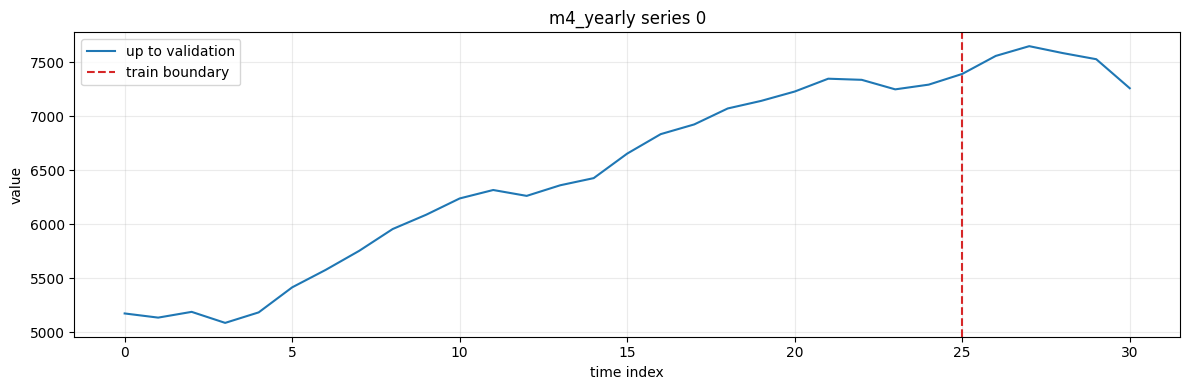

In [6]:
train_entry = _get_train_entry(SERIES_INDEX)
val_entry = _get_validation_entry(SERIES_INDEX)
train_series = _series_from_entry(train_entry)
val_series = _series_from_entry(val_entry)
val_extra = val_series[len(train_series):]

print("Selected series index:", SERIES_INDEX)
print("train length         :", len(train_series))
print("validation length    :", len(val_series))
print("validation\\train len :", len(val_extra))
print("test windows         :", dataset.windows)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(np.arange(len(val_series)), val_series, linewidth=1.5, label="up to validation")
ax.axvline(len(train_series), color="tab:red", linestyle="--", label="train boundary")
ax.set_title(f"{DATASET_NAME} series {SERIES_INDEX}")
ax.set_xlabel("time index")
ax.set_ylabel("value")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Layer 1 — Fit Lengthscale Field (training split)

In [7]:
rng = np.random.default_rng(42)
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)

# ── collect training series ──────────────────────────────────────
print("Collecting training series …")
train_series_list = _collect_train_series(max_series=MAX_SERIES)
print(f"  {len(train_series_list)} usable series")

# ── pool windows from all training series ─────────────────────────
print("Pooling windows …")
ctx_train, tgt_train, meta_train = pool_windows_from_series(
    train_series_list,
    context_length=CONTEXT_LENGTH,
    horizon_length=horizon_length,
    stride=horizon_length,
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    normalization=NORMALIZATION,
    rng=rng,
)
print(f"  pooled {ctx_train.shape[0]} windows, context shape: {ctx_train.shape}")

# ── Layer 1: fit lengthscale field ───────────────────────────────
print("\nFitting Layer 1 (lengthscale field) …")
ell_field = fit_gibbs_lengthscale_field(
    ctx_train, tgt_train,
    block_size_l1=BLOCK_SIZE_L1,
    sigma_n=SIGMA_N_L1,
    amplitude=AMPLITUDE_L1,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    meta_amplitude=META_AMPLITUDE,
    meta_bandwidth=META_BANDWIDTH,
    rng=rng,
)
print(f"  anchors (M_1) : {ell_field.n_anchors}")
print(f"  meta_bandwidth: {ell_field.meta_bandwidth:.4f}")
sample_ell = ell_field.predict_ell(ctx_train[:5])
print(f"  sample ℓ̃ values: {sample_ell}")

  200 usable series
Pooling windows …
  pooled 855 windows, context shape: (855, 8)

Fitting Layer 1 (lengthscale field) …
  anchors (M_1) : 29
  meta_bandwidth: 0.3853
  sample ℓ̃ values: [1.64872023 1.36790607 1.64872127 1.66765195 1.64872127]


## Layer 2 — Fit Nested Kriging Regression (training split)

In [8]:
# ── Layer 2: fit nested kriging regression ───────────────────────
print("Fitting Layer 2 (nested kriging regression) …")
forecaster = NestedKrigingForecaster(
    ell_field,
    block_size=BLOCK_SIZE_L2,
    max_blocks=MAX_BLOCKS_L2,
    sigma_n=SIGMA_N_L2,
    amplitude=AMPLITUDE_L2,
    rng=rng,
).fit(ctx_train, tgt_train)

n_blocks = len(forecaster._fitted_blocks)
block_sizes = [len(b.indices) for b in forecaster._fitted_blocks]
print(f"  Layer-2 blocks (M_2): {n_blocks}")
print(f"  Block sizes: min={min(block_sizes)}, max={max(block_sizes)}, mean={np.mean(block_sizes):.1f}")

Fitting Layer 2 (nested kriging regression) …
  Layer-2 blocks (M_2): 9
  Block sizes: min=55, max=100, mean=95.0


## Short-Term Evaluation: train → validation \ train

Short-term evaluation (train -> validation\train) …


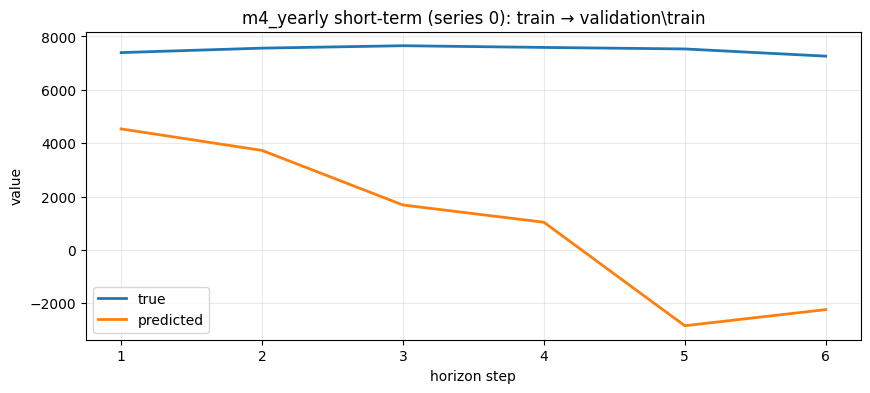

Short-term evaluated : 1 series
Short-term skipped   : 0 series
Mean  relative L2    : 0.886922
Median relative L2   : 0.886922


In [9]:
# ── Short-term forecast: train -> validation\train ────────────────
print("Short-term evaluation (train -> validation\\train) …")
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
n_series_total = len(dataset.hf_dataset)

short_errors, short_naive_errors = [], []
short_skipped = []
plotted = False

for eval_idx in _evaluation_series_indices(n_series_total):
    train_arr = _series_from_entry(_get_train_entry(eval_idx))
    val_arr = _series_from_entry(_get_validation_entry(eval_idx))
    val_extra = val_arr[len(train_arr):]

    if len(train_arr) < CONTEXT_LENGTH:
        short_skipped.append((eval_idx, "train shorter than context_length"))
        continue
    if len(val_extra) < horizon_length:
        short_skipped.append((eval_idx, "validation\\train shorter than horizon_length"))
        continue

    # Instance-normalise using training median/IQR
    if NORMALIZATION == "robust_series":
        loc = float(np.median(train_arr))
        q75, q25 = float(np.percentile(train_arr, 75)), float(np.percentile(train_arr, 25))
        scale = max((q75 - q25) / 1.349, float(np.std(train_arr)), 1e-6)
    else:
        loc, scale = 0.0, 1.0

    query_raw = train_arr[-CONTEXT_LENGTH:]
    query_norm = (query_raw - loc) / scale
    pred_norm = forecaster.predict(query_norm)  # (H,)
    pred = _denorm(pred_norm, loc, scale)

    true_vals = val_extra[:horizon_length]
    err = _mase(true_vals, pred, train_arr, _sp)
    short_errors.append(err)
    short_naive_errors.append(_mase(true_vals, _seasonal_naive(train_arr, horizon_length, _sp), train_arr, _sp))

    if (not EVALUATE_ALL_SERIES and eval_idx == SERIES_INDEX) or (
        EVALUATE_ALL_SERIES and not plotted
    ):
        _plot_forecast(
            true_vals, pred,
            title=f"{DATASET_NAME} short-term (series {eval_idx}): train → validation\\train",
        )
        plotted = True

if short_errors:
    arr = np.asarray(short_errors, dtype=float)
    _n = np.asarray(short_naive_errors, float)
    print(f"Short-term evaluated : {len(short_errors)} series")
    print(f"Short-term skipped   : {len(short_skipped)} series")
    print(f"Mean  MASE           : {float(np.nanmean(arr)):.4f}  (s-naive: {float(np.nanmean(_n)):.4f})")
    print(f"Median MASE          : {float(np.nanmedian(arr)):.4f}  (s-naive: {float(np.nanmedian(_n)):.4f})")
else:
    print("No short-term forecasts could be evaluated.")
    for s in short_skipped:
        print(" ", s)

## Re-Fit on Validation Split (for test evaluation)

In [10]:
# ── Re-fit Layer 1+2 on the validation split ─────────────────────
print("Collecting validation series …")
val_series_list = _collect_val_series(max_series=MAX_SERIES)
print(f"  {len(val_series_list)} usable series")

print("Pooling validation windows …")
ctx_val, tgt_val, meta_val = pool_windows_from_series(
    val_series_list,
    context_length=CONTEXT_LENGTH,
    horizon_length=dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH),
    stride=dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH),
    max_windows_per_series=MAX_WINDOWS_PER_SERIES,
    normalization=NORMALIZATION,
    rng=rng,
)
print(f"  pooled {ctx_val.shape[0]} windows")

print("\nFitting Layer 1 on validation split …")
ell_field_val = fit_gibbs_lengthscale_field(
    ctx_val, tgt_val,
    block_size_l1=BLOCK_SIZE_L1,
    sigma_n=SIGMA_N_L1,
    amplitude=AMPLITUDE_L1,
    log_ell_bounds=(LOG_ELL_LO, LOG_ELL_HI),
    meta_amplitude=META_AMPLITUDE,
    meta_bandwidth=META_BANDWIDTH,
    rng=rng,
)
print(f"  anchors: {ell_field_val.n_anchors}")

print("Fitting Layer 2 on validation split …")
forecaster_val = NestedKrigingForecaster(
    ell_field_val,
    block_size=BLOCK_SIZE_L2,
    max_blocks=MAX_BLOCKS_L2,
    sigma_n=SIGMA_N_L2,
    amplitude=AMPLITUDE_L2,
    rng=rng,
).fit(ctx_val, tgt_val)
print("Done.")

  200 usable series
Pooling validation windows …
  pooled 1055 windows

Fitting Layer 1 on validation split …
  anchors: 36
Fitting Layer 2 on validation split …
Done.


## Long-Term Evaluation: direct forecast on test window 0

Long-term test evaluation …


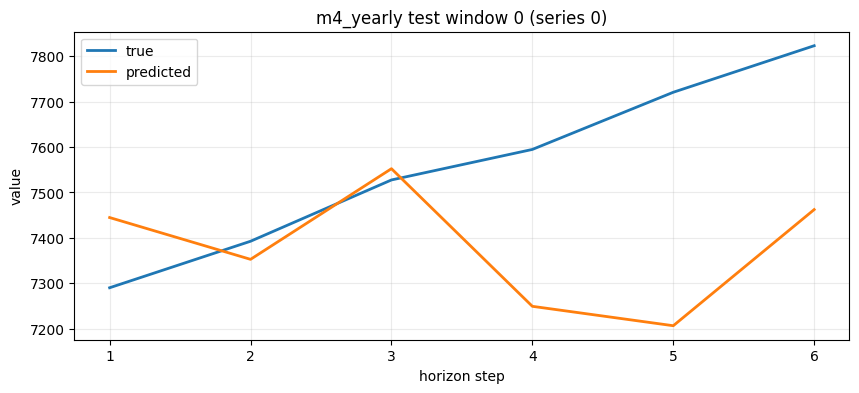

Test evaluated       : 1 series
Test skipped         : 0 series
Mean  relative L2    : 0.001575
Median relative L2   : 0.001575


In [11]:
# ── Long-term: direct test-window evaluation ──────────────────────
print("Long-term test evaluation …")
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)
n_series_total = len(dataset.hf_dataset)

test_errors, test_naive_errors = [], []
test_skipped = []
plotted = False

for eval_idx in _evaluation_series_indices(n_series_total):
    val_arr = _series_from_entry(_get_validation_entry(eval_idx))
    if len(val_arr) < CONTEXT_LENGTH:
        test_skipped.append((eval_idx, "validation shorter than context_length"))
        continue

    # Normalise using validation stats
    if NORMALIZATION == "robust_series":
        loc = float(np.median(val_arr))
        q75, q25 = float(np.percentile(val_arr, 75)), float(np.percentile(val_arr, 25))
        scale = max((q75 - q25) / 1.349, float(np.std(val_arr)), 1e-6)
    else:
        loc, scale = 0.0, 1.0

    _any_win = False
    for _w in range(dataset.windows if MAX_TEST_WINDOWS is None else min(MAX_TEST_WINDOWS, dataset.windows)):
        try:
            test_ctx_entry, test_lbl_entry = _get_test_pair(eval_idx, _w)
        except IndexError:
            continue
        test_ctx = _series_from_entry(test_ctx_entry)
        test_lbl = _series_from_entry(test_lbl_entry)
        if len(test_ctx) < CONTEXT_LENGTH or len(test_lbl) < horizon_length:
            continue
        query_raw = test_ctx[-CONTEXT_LENGTH:]
        query_norm = (query_raw - loc) / scale
        pred_norm = forecaster_val.predict(query_norm)
        pred = _denorm(pred_norm, loc, scale)
        true_vals = test_lbl[:horizon_length]
        test_errors.append(_mase(true_vals, pred, val_arr, _sp))
        test_naive_errors.append(_mase(true_vals, _seasonal_naive(val_arr, horizon_length, _sp), val_arr, _sp))
        _any_win = True
        if (not EVALUATE_ALL_SERIES and eval_idx == SERIES_INDEX) or (
            EVALUATE_ALL_SERIES and not plotted
        ):
            _plot_forecast(true_vals, pred,
                           title=f"{DATASET_NAME} test w{_w} (series {eval_idx})")
            plotted = True
    if not _any_win:
        test_skipped.append((eval_idx, "no valid test windows"))
        continue

if test_errors:
    arr = np.asarray(test_errors, dtype=float)
    _n = np.asarray(test_naive_errors, float)
    print(f"Test evaluated       : {len(test_errors)} windows")
    print(f"Test skipped         : {len(test_skipped)} series")
    print(f"Mean  MASE           : {float(np.nanmean(arr)):.4f}  (s-naive: {float(np.nanmean(_n)):.4f})")
    print(f"Median MASE          : {float(np.nanmedian(arr)):.4f}  (s-naive: {float(np.nanmedian(_n)):.4f})")
else:
    print("No test forecasts could be evaluated.")
    for s in test_skipped:
        print(" ", s)

## Posterior Uncertainty: selected series

Computing posterior uncertainty for series 0 …
  posterior std (denormalised): 357.8973


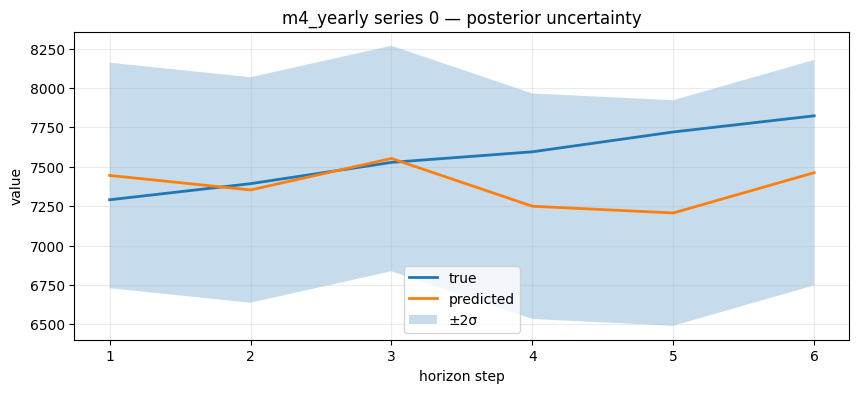

In [12]:
# ── Posterior uncertainty for the selected series ─────────────────
print("Computing posterior uncertainty for series", SERIES_INDEX, "…")
horizon_length = dataset.prediction_length if HORIZON_LENGTH is None else int(HORIZON_LENGTH)

val_arr = _series_from_entry(_get_validation_entry(SERIES_INDEX))
if NORMALIZATION == "robust_series":
    loc_u = float(np.median(val_arr))
    q75_u, q25_u = float(np.percentile(val_arr, 75)), float(np.percentile(val_arr, 25))
    scale_u = max((q75_u - q25_u) / 1.349, float(np.std(val_arr)), 1e-6)
else:
    loc_u, scale_u = 0.0, 1.0

test_ctx_entry, test_lbl_entry = _get_test_pair(SERIES_INDEX, 0)
test_ctx = _series_from_entry(test_ctx_entry)
test_lbl = _series_from_entry(test_lbl_entry)

query_raw = test_ctx[-CONTEXT_LENGTH:]
query_norm = (query_raw - loc_u) / scale_u

pred_norm, sigma2 = forecaster_val.predict_with_uncertainty(query_norm)
pred = _denorm(pred_norm, loc_u, scale_u)
true_vals = test_lbl[:horizon_length]
std_denorm = float(np.sqrt(max(sigma2, 0.0))) * scale_u

print(f"  posterior std (denormalised): {std_denorm:.4f}")

t = np.arange(1, horizon_length + 1)
plt.figure(figsize=(10, 4))
plt.plot(t, true_vals, label="true", linewidth=2)
plt.plot(t, pred, label="predicted", linewidth=2)
plt.fill_between(
    t,
    pred - 2 * std_denorm,
    pred + 2 * std_denorm,
    alpha=0.25,
    label="±2σ",
)
plt.title(f"{DATASET_NAME} series {SERIES_INDEX} — posterior uncertainty")
plt.xlabel("horizon step")
plt.ylabel("value")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [13]:
# ── Export model state for cross-dataset nested kriging layer ────────────────
from pathlib import Path
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.getcwd()), ".."))

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

safe_name = DATASET_NAME.replace("/", "__")
save_path = models_dir / f"{safe_name}.npz"
forecaster.save_state(save_path, dataset_name=DATASET_NAME)
print(f"Saved model state → {save_path}  ({len(forecaster._fitted_blocks)} blocks)")


Saved model state → ../models/m4_yearly.npz  (9 blocks)


In [ ]:
# ── Save metrics and hyperparameters to JSON ────────────────────────────────
import json as _nk_json
import numpy as _nk_np
_nk_results_dir = REPO_ROOT / "experiments" / "results"
_nk_results_dir.mkdir(parents=True, exist_ok=True)

_nk_hyperparams = {
    "DATASET_NAME":           DATASET_NAME,
    "CONTEXT_LENGTH":         CONTEXT_LENGTH,
    "HORIZON_LENGTH":         HORIZON_LENGTH,
    "BLOCK_SIZE_L1":          BLOCK_SIZE_L1,
    "BLOCK_SIZE_L2":          BLOCK_SIZE_L2,
    "MAX_SERIES":             MAX_SERIES,
    "MAX_BLOCKS_L2":          MAX_BLOCKS_L2,
    "MAX_WINDOWS_PER_SERIES": MAX_WINDOWS_PER_SERIES,
    "SIGMA_N_L1":             SIGMA_N_L1,
    "SIGMA_N_L2":             SIGMA_N_L2,
    "AMPLITUDE_L1":           AMPLITUDE_L1,
    "AMPLITUDE_L2":           AMPLITUDE_L2,
    "LOG_ELL_LO":             LOG_ELL_LO,
    "LOG_ELL_HI":             LOG_ELL_HI,
    "META_AMPLITUDE":         META_AMPLITUDE,
    "META_BANDWIDTH":         META_BANDWIDTH,
    "NORMALIZATION":          NORMALIZATION,
    "SERIES_INDEX":           SERIES_INDEX,
    "EVALUATE_ALL_SERIES":    EVALUATE_ALL_SERIES,
    "EVAL_SERIES_LIMIT":      EVAL_SERIES_LIMIT,
}

_nk_short = [float(e) for e in short_errors] if 'short_errors' in vars() and short_errors else []
_nk_test  = [float(e) for e in test_errors]  if 'test_errors'  in vars() and test_errors  else []

# naive MASE arrays — variable names differ by notebook family
_nk_short_n = [float(e) for e in (
    globals().get('short_naive_errors',        # univariate / missing
    globals().get('all_naive_errors', [])))    # multivariate
]
_nk_test_n  = [float(e) for e in (
    globals().get('test_naive_errors',         # univariate
    globals().get('all_test_naive_errors',     # multivariate
    globals().get('naive_errors', []))))       # missing-data (long eval reuses this)
]

_nk_out = {
    "hyperparameters":    _nk_hyperparams,
    "short_term_MASE":  _nk_short,
    "test_MASE":        _nk_test,
    "metrics": {
        "short_mean_MASE":   float(_nk_np.nanmean(_nk_short))   if _nk_short else None,
        "short_median_MASE": float(_nk_np.nanmedian(_nk_short)) if _nk_short else None,
        "short_n_evaluated":  len(_nk_short),
        "test_mean_MASE":    float(_nk_np.nanmean(_nk_test))    if _nk_test  else None,
        "test_median_MASE":  float(_nk_np.nanmedian(_nk_test))  if _nk_test  else None,
        "test_n_evaluated":   len(_nk_test),
        "test_mean_s_naive_MASE":    float(_nk_np.nanmean(_nk_test_n))    if '_nk_test_n' in dir() and _nk_test_n  else None,
    },
}

_nk_safe  = DATASET_NAME.replace("/", "__")
_nk_fpath = _nk_results_dir / f"{_nk_safe}.json"
with open(_nk_fpath, "w") as _nk_f:
    _nk_json.dump(_nk_out, _nk_f, indent=2)
print(f"Results saved → {_nk_fpath}")
